In [2]:
import heapq, random, time
from collections import deque
import numpy as np
import matplotlib.pyplot as plt

def make_grid(n=20, p=0.2, seed=0):
    random.seed(seed)
    g = [[1 if random.random() < p else 0 for _ in range(n)] for _ in range(n)]
    g[0][0] = 0; g[n-1][n-1] = 0
    return g

def neighbors(g, r, c):
    for dr, dc in [(1,0),(-1,0),(0,1),(0,-1)]:
        nr, nc = r+dr, c+dc
        if 0 <= nr < len(g) and 0 <= nc < len(g[0]) and g[nr][nc] == 0:
            yield nr, nc

def build_path(parent, goal):
    path, cur = [], goal
    while cur is not None:
        path.append(cur); cur = parent[cur]
    return path[::-1]

In [3]:
def bfs(g, start, goal):
    q = deque([start]); parent = {start: None}; explored = 0
    while q:
        cur = q.popleft(); explored += 1
        if cur == goal: return build_path(parent, goal), explored
        for nb in neighbors(g, *cur):
            if nb not in parent:
                parent[nb] = cur; q.append(nb)
    return None, explored

def astar(g, start, goal, use_h=True):   # use_h=False  ->  Dijkstra
    h = (lambda p: abs(p[0]-goal[0]) + abs(p[1]-goal[1])) if use_h else (lambda p: 0)
    pq = [(h(start), 0, start)]
    parent = {start: None}; cost = {start: 0}; explored = 0
    while pq:
        _, d, cur = heapq.heappop(pq)
        if d > cost[cur]: continue
        explored += 1
        if cur == goal: return build_path(parent, goal), explored
        for nb in neighbors(g, *cur):
            nd = d + 1
            if nb not in cost or nd < cost[nb]:
                cost[nb] = nd; parent[nb] = cur
                heapq.heappush(pq, (nd + h(nb), nd, nb))
    return None, explored

def dijkstra(g, s, t):
    return astar(g, s, t, use_h=False)

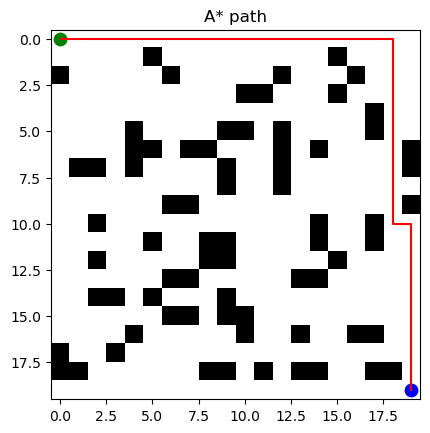

In [4]:
def show(g, path, start, goal, title=""):
    plt.imshow(np.array(g, dtype=float), cmap="gray_r")
    if path:
        ys, xs = zip(*path); plt.plot(xs, ys, "r-")
    plt.scatter(start[1], start[0], c="green", s=80)
    plt.scatter(goal[1], goal[0], c="blue", s=80)
    plt.title(title); plt.show()

def make_solvable(n=20, p=0.2, seed=0):
    while True:
        g = make_grid(n, p, seed)
        if bfs(g, (0,0), (n-1,n-1))[0]: return g
        seed += 1

n = 20
g = make_solvable(n)
start, goal = (0,0), (n-1,n-1)
path, _ = astar(g, start, goal)
show(g, path, start, goal, "A* path")

In [5]:
algos = [("BFS", bfs), ("Dijkstra", dijkstra), ("A*", astar)]
results = {name: [] for name, _ in algos}

for seed in range(20):                      # 20 different maps
    g = make_solvable(n, 0.2, seed)
    for name, fn in algos:
        t0 = time.perf_counter()
        path, explored = fn(g, start, goal)
        ms = (time.perf_counter() - t0) * 1000
        results[name].append((len(path)-1, explored, ms))

print(f"{'Algorithm':10} {'PathLen':>8} {'Explored':>9} {'Time(ms)':>9}")
for name, _ in algos:
    arr = np.array(results[name]).mean(axis=0)
    print(f"{name:10} {arr[0]:8.1f} {arr[1]:9.1f} {arr[2]:9.3f}")

Algorithm   PathLen  Explored  Time(ms)
BFS            38.6     316.5     0.755
Dijkstra       38.6     316.6     1.034
A*             38.6     214.6     0.751


Goal reached: True | Replans: 3 | Steps: 38


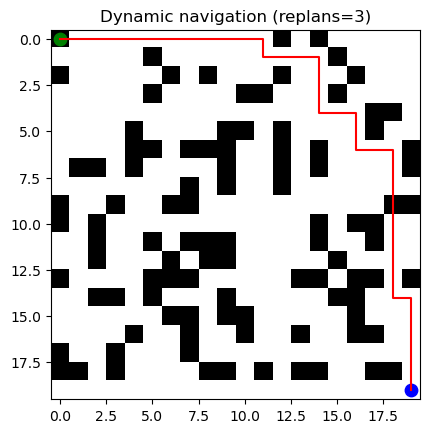

In [6]:
def navigate_dynamic(g, start, goal, new_per_step=1, seed=1):
    random.seed(seed)
    g = [row[:] for row in g]
    pos, replans = start, 0
    trail = [pos]
    path, _ = astar(g, pos, goal)
    while path and pos != goal:
        for _ in range(new_per_step):            # new obstacle
            r, c = random.randrange(len(g)), random.randrange(len(g[0]))
            if (r, c) not in (pos, goal) and g[r][c] == 0:
                g[r][c] = 1
        if any(g[r][c] == 1 for r, c in path):   # blocked path
            path, _ = astar(g, pos, goal); replans += 1
            if not path: return trail, replans, False, g
        pos = path[1]; trail.append(pos); path = path[1:]
    return trail, replans, pos == goal, g

g = make_solvable(n)
trail, replans, ok, g2 = navigate_dynamic(g, start, goal, new_per_step=1)
print("Goal reached:", ok, "| Replans:", replans, "| Steps:", len(trail)-1)
show(g2, trail, start, goal, f"Dynamic navigation (replans={replans})")

Density vs avg explored nodes
0.1 {'BFS': 808.2, 'Dijkstra': 808.3, 'A*': 707.4}
0.2 {'BFS': 713.8, 'Dijkstra': 714.1, 'A*': 493.0}
0.3 {'BFS': 583.1, 'Dijkstra': 585.8, 'A*': 273.2}

Grid size vs avg explored nodes
20 {'BFS': 316.5, 'Dijkstra': 316.6, 'A*': 214.6}
40 {'BFS': 1272.0, 'Dijkstra': 1272.1, 'A*': 828.7}
60 {'BFS': 2881.2, 'Dijkstra': 2881.4, 'A*': 1836.4}


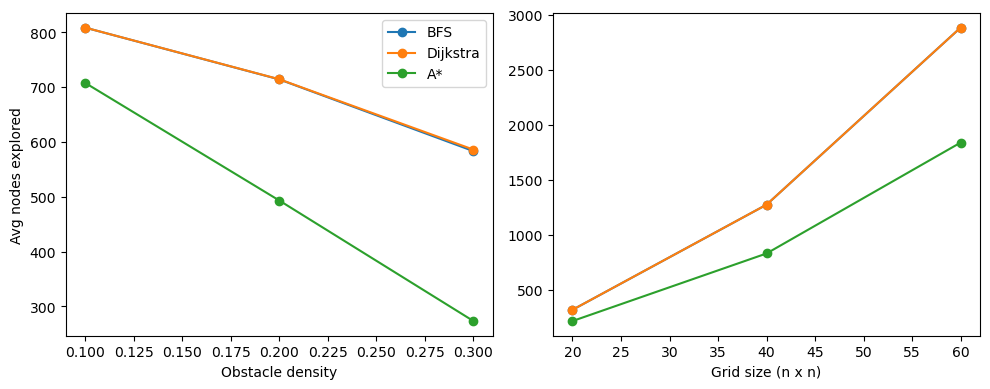

In [7]:
def run_experiment(n, p, maps=20):
    s, t = (0, 0), (n-1, n-1)
    out = {"BFS": [], "Dijkstra": [], "A*": []}
    for seed in range(maps):
        g = make_solvable(n, p, seed)
        for name, fn in [("BFS", bfs), ("Dijkstra", dijkstra), ("A*", astar)]:
            _, explored = fn(g, s, t)
            out[name].append(explored)
    return {k: np.mean(v) for k, v in out.items()}

# (a) changing the obstacle density, grid size 30 fixed
densities = [0.1, 0.2, 0.3]
res_d = {p: run_experiment(30, p) for p in densities}
print("Density vs avg explored nodes")
for p, r in res_d.items():
    print(p, {k: round(v, 1) for k, v in r.items()})

# (b) changing the grid size, density 0.2 fixed
sizes = [20, 40, 60]
res_s = {n_: run_experiment(n_, 0.2) for n_ in sizes}
print("\nGrid size vs avg explored nodes")
for n_, r in res_s.items():
    print(n_, {k: round(v, 1) for k, v in r.items()})

# graph
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for name in ["BFS", "Dijkstra", "A*"]:
    ax[0].plot(densities, [res_d[p][name] for p in densities], marker="o", label=name)
    ax[1].plot(sizes, [res_s[s_][name] for s_ in sizes], marker="o", label=name)
ax[0].set_xlabel("Obstacle density"); ax[0].set_ylabel("Avg nodes explored")
ax[1].set_xlabel("Grid size (n x n)")
ax[0].legend(); plt.tight_layout(); plt.show()

In [8]:
import math

def h_fn(name, goal):
    def manhattan(p): return abs(p[0]-goal[0]) + abs(p[1]-goal[1])
    def euclid(p):    return math.hypot(p[0]-goal[0], p[1]-goal[1])
    def octile(p):
        dx, dy = abs(p[0]-goal[0]), abs(p[1]-goal[1])
        return (dx + dy) + (math.sqrt(2) - 2) * min(dx, dy)
    return {"manhattan": manhattan, "euclidean": euclid, "octile": octile}[name]

def nbrs8(g, r, c):
    for dr, dc in [(1,0),(-1,0),(0,1),(0,-1),(1,1),(1,-1),(-1,1),(-1,-1)]:
        nr, nc = r+dr, c+dc
        if 0 <= nr < len(g) and 0 <= nc < len(g[0]) and g[nr][nc] == 0:
            if dr and dc and (g[r+dr][c] == 1 or g[r][c+dc] == 1):
                continue                      
            yield (nr, nc), (math.sqrt(2) if dr and dc else 1)

def astar2(g, start, goal, hname, diag):
    h = h_fn(hname, goal)
    pq = [(h(start), 0, start)]
    parent, cost, explored = {start: None}, {start: 0}, 0
    while pq:
        _, d, cur = heapq.heappop(pq)
        if d > cost[cur]: continue
        explored += 1
        if cur == goal: return build_path(parent, goal), d, explored
        moves = nbrs8(g, *cur) if diag else ((nb, 1) for nb in neighbors(g, *cur))
        for nb, w in moves:
            nd = d + w
            if nb not in cost or nd < cost[nb]:
                cost[nb] = nd; parent[nb] = cur
                heapq.heappush(pq, (nd + h(nb), nd, nb))
    return None, None, explored

configs = [("manhattan", False), ("euclidean", False),
           ("euclidean", True), ("octile", True)]
rows = {c: [] for c in configs}
for seed in range(20):
    g = make_solvable(30, 0.2, seed)
    for hname, diag in configs:
        _, cost_, explored = astar2(g, (0, 0), (29, 29), hname, diag)
        rows[(hname, diag)].append((cost_, explored))

print(f"{'Heuristic':10} {'Moves':6} {'AvgCost':>8} {'Explored':>9}")
for (hname, diag), v in rows.items():
    a = np.mean(v, axis=0)
    print(f"{hname:10} {'8-dir' if diag else '4-dir':6} {a[0]:8.1f} {a[1]:9.1f}")

Heuristic  Moves   AvgCost  Explored
manhattan  4-dir      58.4     492.9
euclidean  4-dir      58.4     625.5
euclidean  8-dir      47.9     369.1
octile     8-dir      47.9     284.2


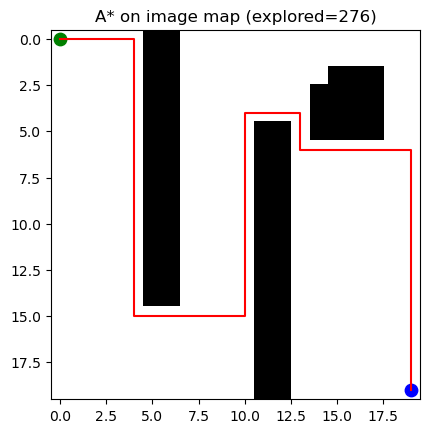

In [9]:
import cv2


img = np.full((400, 400, 3), 255, np.uint8)
cv2.rectangle(img, (100, 0), (130, 300), (0, 0, 0), -1)
cv2.rectangle(img, (220, 100), (250, 400), (0, 0, 0), -1)
cv2.circle(img, (320, 80), 40, (0, 0, 0), -1)
cv2.imwrite("map.png", img)

def image_to_grid(path, cell=20):
    im = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    _, bw = cv2.threshold(im, 128, 255, cv2.THRESH_BINARY)
    rows, cols = im.shape[0] // cell, im.shape[1] // cell
    g = []
    for r in range(rows):
        row = []
        for c in range(cols):
            block = bw[r*cell:(r+1)*cell, c*cell:(c+1)*cell]
            row.append(1 if (block == 0).mean() > 0.3 else 0)    
        g.append(row)
    return g

g = image_to_grid("map.png")
g[0][0] = 0; g[-1][-1] = 0
s, t = (0, 0), (len(g)-1, len(g[0])-1)
path, explored = astar(g, s, t)
show(g, path, s, t, f"A* on image map (explored={explored})")

A*        path length: 38 | time (s): 0.0011
Q-Learning path length: 38 | training time (s): 2.31 | episodes: 3000


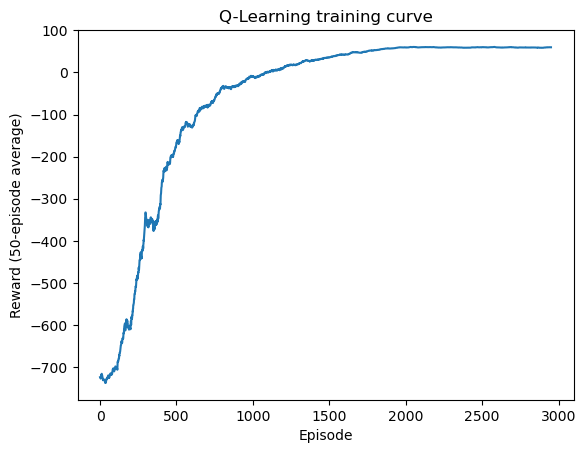

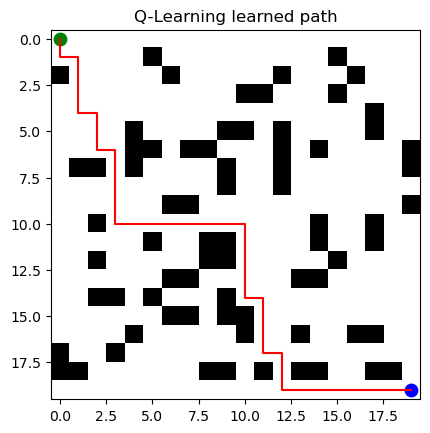

In [10]:
def q_learning(g, start, goal, episodes=3000, alpha=0.5, gamma=0.95,
               max_steps=400, seed=0):
    rng = random.Random(seed)
    n = len(g)
    actions = [(1, 0), (-1, 0), (0, 1), (0, -1)]
    Q = np.zeros((n, n, 4))
    rewards = []
    for ep in range(episodes):
        eps = max(0.05, 1.0 - ep / (episodes * 0.7))     
        s, total = start, 0
        for _ in range(max_steps):
            if rng.random() < eps:
                a = rng.randrange(4)                      # explore
            else:
                qs = Q[s[0], s[1]]
                a = int(rng.choice(np.flatnonzero(qs == qs.max())))   # exploit
            nr, nc = s[0] + actions[a][0], s[1] + actions[a][1]
            if 0 <= nr < n and 0 <= nc < n and g[nr][nc] == 0:
                ns, r = (nr, nc), -1                      # normal step
            else:
                ns, r = s, -5                             # collision with wall
            done = ns == goal
            if done: r = 100
            target = r + (0 if done else gamma * Q[ns[0], ns[1]].max())
            Q[s[0], s[1], a] += alpha * (target - Q[s[0], s[1], a])
            s, total = ns, total + r
            if done: break
        rewards.append(total)
    return Q, rewards

def greedy_path(Q, g, start, goal, max_steps=200):
    actions = [(1, 0), (-1, 0), (0, 1), (0, -1)]
    n, s, path = len(g), start, [start]
    for _ in range(max_steps):
        if s == goal: return path
        a = int(np.argmax(Q[s[0], s[1]]))
        nr, nc = s[0] + actions[a][0], s[1] + actions[a][1]
        if not (0 <= nr < n and 0 <= nc < n and g[nr][nc] == 0):
            return None
        s = (nr, nc); path.append(s)
    return None

n = 20
g = make_solvable(n)
start, goal = (0, 0), (n - 1, n - 1)

t0 = time.perf_counter()
Q, rewards = q_learning(g, start, goal)
t_q = time.perf_counter() - t0
q_path = greedy_path(Q, g, start, goal)

t0 = time.perf_counter()
a_path, _ = astar(g, start, goal)
t_a = time.perf_counter() - t0

print("A*        path length:", len(a_path) - 1, "| time (s):", round(t_a, 4))
print("Q-Learning path length:", (len(q_path) - 1) if q_path else "fail",
      "| training time (s):", round(t_q, 2), "| episodes: 3000")

smooth = np.convolve(rewards, np.ones(50) / 50, mode="valid")
plt.plot(smooth); plt.xlabel("Episode"); plt.ylabel("Reward (50-episode average)")
plt.title("Q-Learning training curve"); plt.show()
show(g, q_path, start, goal, "Q-Learning learned path")

In [11]:
ok, same = 0, 0
for seed in range(10):
    g = make_solvable(20, 0.2, seed)
    Q, _ = q_learning(g, (0, 0), (19, 19), seed=seed)
    qp = greedy_path(Q, g, (0, 0), (19, 19))
    ap, _ = astar(g, (0, 0), (19, 19))
    if qp:
        ok += 1
        same += (len(qp) == len(ap))
print(f"Reached goal: {ok}/10 | Same length as A*: {same}/10")

Reached goal: 10/10 | Same length as A*: 10/10


In [12]:
from sklearn.ensemble import RandomForestRegressor

def dist_from_goal(g, goal):
    
    dist = {goal: 0}; q = deque([goal])
    while q:
        cur = q.popleft()
        for nb in neighbors(g, *cur):
            if nb not in dist:
                dist[nb] = dist[cur] + 1; q.append(nb)
    return dist

def cell_features(g, goal):
    arr = np.array(g); n = len(g)
    pad = np.pad(arr, 2, constant_values=1)          # let border=obstacle 
    feats = {}
    for r in range(n):
        for c in range(n):
            if g[r][c] == 1: continue
            win = pad[r:r+5, c:c+5]                  # cell surrounding 5x5 area
            feats[(r, c)] = [r, c, goal[0]-r, goal[1]-c,
                             abs(goal[0]-r) + abs(goal[1]-c),   # Manhattan
                             win.mean(), arr.mean()]            # local and global obstacle density
    return feats

def build_data(seeds, n=20, p=0.2):
    goal = (n-1, n-1); X, y = [], []
    for seed in seeds:
        g = make_solvable(n, p, seed)
        dist = dist_from_goal(g, goal)
        for cell, f in cell_features(g, goal).items():
            if cell in dist:
                X.append(f); y.append(dist[cell])
    return np.array(X), np.array(y)


X_train, y_train = build_data(range(1000, 1200))
X_test,  y_test  = build_data(range(0, 20))
print("Train rows:", X_train.shape, "| Test rows:", X_test.shape)

model = RandomForestRegressor(n_estimators=100, max_depth=12, n_jobs=-1, random_state=0)
model.fit(X_train, y_train)

pred = model.predict(X_test)
print("Manhattan MAE:", round(np.mean(np.abs(X_test[:, 4] - y_test)), 2))
print("Learned   MAE:", round(np.mean(np.abs(pred - y_test)), 2))

Train rows: (63674, 7) | Test rows: (6333, 7)
Manhattan MAE: 1.26
Learned   MAE: 1.26


In [13]:
def cell_features(g, goal):
    arr = np.array(g); n = len(g)
    pad = np.pad(arr, 4, constant_values=1)
    feats = {}
    for r in range(n):
        for c in range(n):
            if g[r][c] == 1: continue
            w3 = pad[r+3:r+6, c+3:c+6].mean()
            w5 = pad[r+2:r+7, c+2:c+7].mean()
            w9 = pad[r:r+9, c:c+9].mean()
            box = arr[min(r, goal[0]):max(r, goal[0])+1,
                      min(c, goal[1]):max(c, goal[1])+1]      # rectangle between cell and goal
            feats[(r, c)] = [r, c, goal[0]-r, goal[1]-c,
                             abs(goal[0]-r) + abs(goal[1]-c),   # index 4 = Manhattan
                             w3, w5, w9, box.mean(), box.sum(), arr.mean()]
    return feats

X_train, y_train = build_data(range(1000, 1200))
X_test,  y_test  = build_data(range(0, 20))
man_tr, man_te = X_train[:, 4], X_test[:, 4]

model = RandomForestRegressor(n_estimators=100, max_depth=12, n_jobs=-1, random_state=0)
model.fit(X_train, y_train - man_tr)               # residual 
pred = man_te + model.predict(X_test)

print("Manhattan MAE:", round(np.mean(np.abs(man_te - y_test)), 3))
print("Learned   MAE:", round(np.mean(np.abs(pred - y_test)), 3))
print("Avg signed error (pred - true):", round(np.mean(pred - y_test), 3))

Manhattan MAE: 1.256
Learned   MAE: 1.036
Avg signed error (pred - true): -0.013


In [14]:
def astar_h(g, start, goal, h):
    pq = [(h[start], 0, start)]
    parent, cost, explored = {start: None}, {start: 0}, 0
    while pq:
        _, d, cur = heapq.heappop(pq)
        if d > cost[cur]: continue
        explored += 1
        if cur == goal: return build_path(parent, goal), explored
        for nb in neighbors(g, *cur):
            nd = d + 1
            if nb not in cost or nd < cost[nb]:
                cost[nb] = nd; parent[nb] = cur
                heapq.heappush(pq, (nd + h[nb], nd, nb))
    return None, explored

def heuristics_for_map(g, goal, model):
    feats = cell_features(g, goal)
    cells = list(feats.keys())
    Xm = np.array([feats[c] for c in cells])
    manh = Xm[:, 4]
    learned = manh + model.predict(Xm)
    h_m = dict(zip(cells, manh))
    h_l = dict(zip(cells, learned))
    h_max = dict(zip(cells, np.maximum(learned, manh)))   
    return h_m, h_l, h_max

names = ["Manhattan", "Learned", "Learned>=Manhattan"]
res = {k: [] for k in names}
s, t = (0, 0), (19, 19)

for seed in range(20):                      
    g = make_solvable(20, 0.2, seed)
    opt_len = len(bfs(g, s, t)[0]) - 1      #  shortest path
    for name, h in zip(names, heuristics_for_map(g, t, model)):
        path, ex = astar_h(g, s, t, h)
        res[name].append((ex, len(path) - 1, (len(path) - 1) == opt_len))

print(f"{'Heuristic':20} {'Explored':>9} {'PathLen':>8} {'Optimal%':>9}")
for name in names:
    a = np.array(res[name], dtype=float)
    print(f"{name:20} {a[:,0].mean():9.1f} {a[:,1].mean():8.2f} {100*a[:,2].mean():8.0f}%")

Heuristic             Explored  PathLen  Optimal%
Manhattan                214.6    38.60      100%
Learned                  113.5    39.00       90%
Learned>=Manhattan       113.5    39.00       90%


In [15]:
def eval_setting(p, maps=50, n=20, seed0=2000):
    s, t = (0, 0), (n-1, n-1)
    out = {"Manhattan": [], "Learned": []}
    for seed in range(seed0, seed0 + maps):
        g = make_solvable(n, p, seed)
        opt = len(bfs(g, s, t)[0]) - 1
        h_m, h_l, _ = heuristics_for_map(g, t, model)
        for name, h in [("Manhattan", h_m), ("Learned", h_l)]:
            path, ex = astar_h(g, s, t, h)
            out[name].append((ex, len(path) - 1, (len(path) - 1) == opt))
    return out

for p in [0.1, 0.2, 0.3]:
    out = eval_setting(p)
    print(f"\nDensity {p}")
    print(f"{'Heuristic':10} {'Explored':>9} {'PathLen':>8} {'Optimal%':>9}")
    for name, v in out.items():
        a = np.array(v, dtype=float)
        print(f"{name:10} {a[:,0].mean():9.1f} {a[:,1].mean():8.2f} {100*a[:,2].mean():8.0f}%")


Density 0.1
Heuristic   Explored  PathLen  Optimal%
Manhattan      320.8    38.00      100%
Learned        107.8    38.00      100%

Density 0.2
Heuristic   Explored  PathLen  Optimal%
Manhattan      243.9    38.00      100%
Learned        115.9    38.08       96%

Density 0.3
Heuristic   Explored  PathLen  Optimal%
Manhattan      149.6    39.80      100%
Learned        126.3    39.84       98%


In [16]:
def astar_tb(g, start, goal, h):
   
    pq = [(h[start], 0, start)]
    parent, cost, explored = {start: None}, {start: 0}, 0
    while pq:
        f, negd, cur = heapq.heappop(pq)
        d = -negd
        if d > cost[cur]: continue
        explored += 1
        if cur == goal: return build_path(parent, goal), explored
        for nb in neighbors(g, *cur):
            nd = d + 1
            if nb not in cost or nd < cost[nb]:
                cost[nb] = nd; parent[nb] = cur
                heapq.heappush(pq, (nd + h[nb], -nd, nb))
    return None, explored

def eval_timed(p, maps=50, n=20, seed0=3000):
    s, t = (0, 0), (n-1, n-1)
    rows = {"Manhattan": [], "Manhattan+tiebreak": [], "Learned": [], "Learned+tiebreak": []}
    for seed in range(seed0, seed0 + maps):
        g = make_solvable(n, p, seed)
        opt = len(bfs(g, s, t)[0]) - 1
        t0 = time.perf_counter()
        h_m, h_l, _ = heuristics_for_map(g, t, model)
        t_feat = time.perf_counter() - t0            # features + time of prediction
        runs = [("Manhattan", astar_h, h_m, 0), ("Manhattan+tiebreak", astar_tb, h_m, 0),
                ("Learned", astar_h, h_l, t_feat), ("Learned+tiebreak", astar_tb, h_l, t_feat)]
        for name, fn, h, extra in runs:
            t0 = time.perf_counter()
            path, ex = fn(g, s, t, h)
            ms = (time.perf_counter() - t0 + extra) * 1000
            rows[name].append((ex, len(path) - 1, (len(path) - 1) == opt, ms))
    return rows

rows = eval_timed(0.2)
print(f"{'Heuristic':20} {'Explored':>9} {'PathLen':>8} {'Optimal%':>9} {'Time(ms)':>9}")
for name, v in rows.items():
    a = np.array(v, dtype=float)
    print(f"{name:20} {a[:,0].mean():9.1f} {a[:,1].mean():8.2f} {100*a[:,2].mean():8.0f}% {a[:,3].mean():9.2f}")

Heuristic             Explored  PathLen  Optimal%  Time(ms)
Manhattan                230.2    38.00      100%      0.88
Manhattan+tiebreak        66.9    38.00      100%      0.28
Learned                  110.2    38.00      100%     32.14
Learned+tiebreak         109.2    38.00      100%     32.15
